# Making the line plots
These aren't in the main text, but the supplemental. The one advantage of this plot is it's easier to track AR-Day precipitation over time periods much easier compared to the box-and-whisker plots.

In [1]:
import xarray as xa
import matplotlib.pyplot as plt
from matplotlib import cbook
import numpy as np
import sys
sys.path.append("..")
import fmap as fm
import regionmask
import cftime
import geopandas as gpd
import pandas as pd
from glob import glob
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import pickle

ERROR 1: PROJ: proj_create_from_database: Open of /glade/u/home/tcorrie/.conda/envs/rmask/share/proj failed


The next three cells function the same as in the boxplots .ipynb file

In [2]:
wus_db = gpd.read_file('../watersheds_WUS.geojson', driver='GeoJSON')[['huc4', 'name', 'geometry']]

In [3]:
prec_ARday_all = pickle.load(open('/glade/work/tcorrie/ARdata/pmean/prec_mean_all.pkl', 'rb'))

In [4]:
def flier_colors(bp, color):

    for box in bp['boxes']:
        box.set(color = 'red')
        
    for patch in bp['boxes']:
        patch.set_facecolor('white')

    for whisker in bp['whiskers']:
        whisker.set(color ='red')
    
    # changing color and linewidth of
    for cap in bp['caps']:
        cap.set(color = 'red')

def get_flier_data(data):
    bstat = cbook.boxplot_stats(data, whis=(2.5, 97.5))#[0]['fliers']
    bdata = bstat[0]['fliers'][np.where(bstat[0]['fliers'] > bstat[0]['whishi'])]
    return bdata

def box_mean(data):
    return cbook.boxplot_stats(data)[0]['mean']

/glade/derecho/scratch/tcorrie/tmp/ipykernel_79286/3504411223.py:97: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fx, ax = plt.subplots(1, 1, figsize=(16, 6))


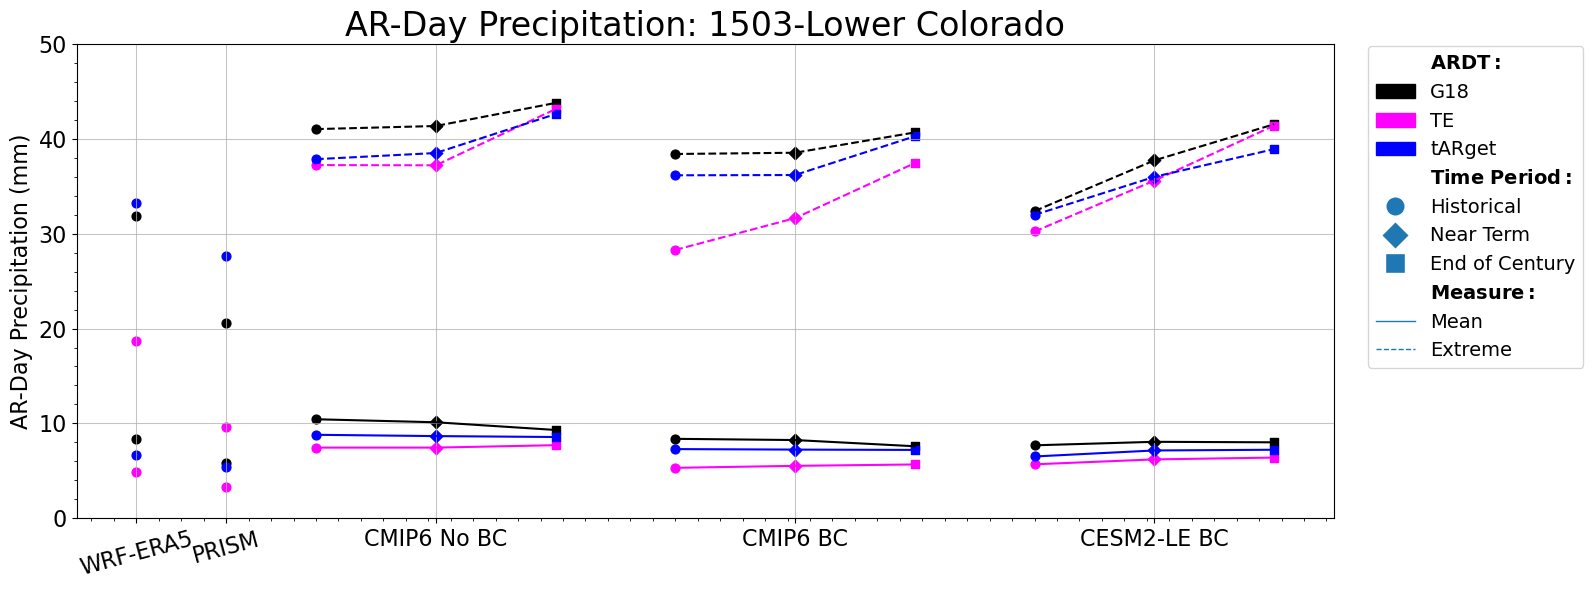

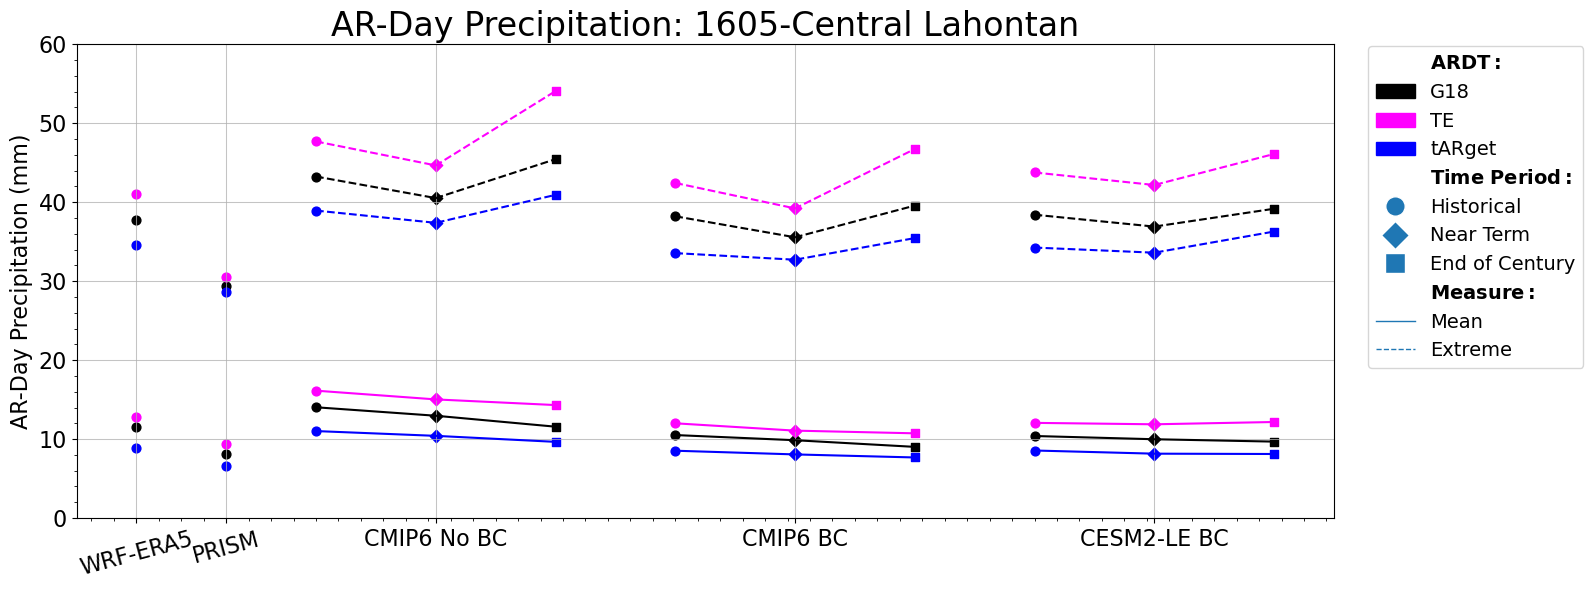

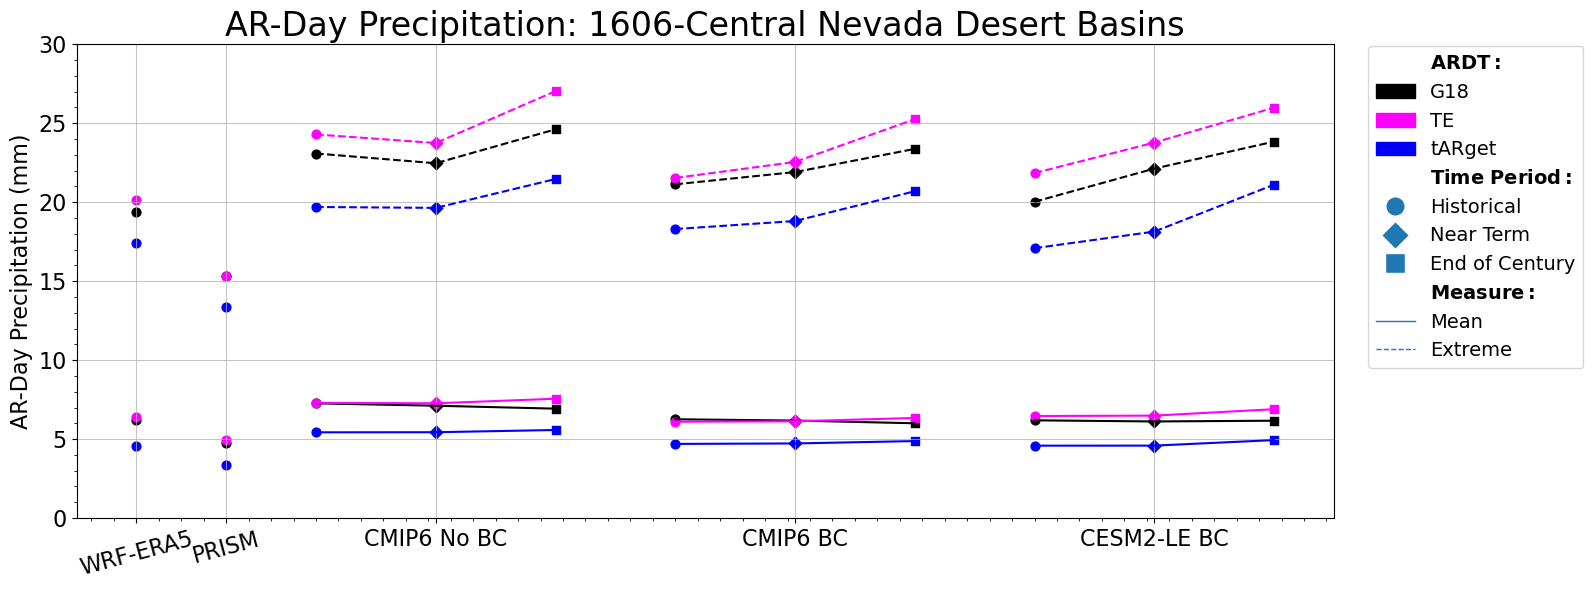

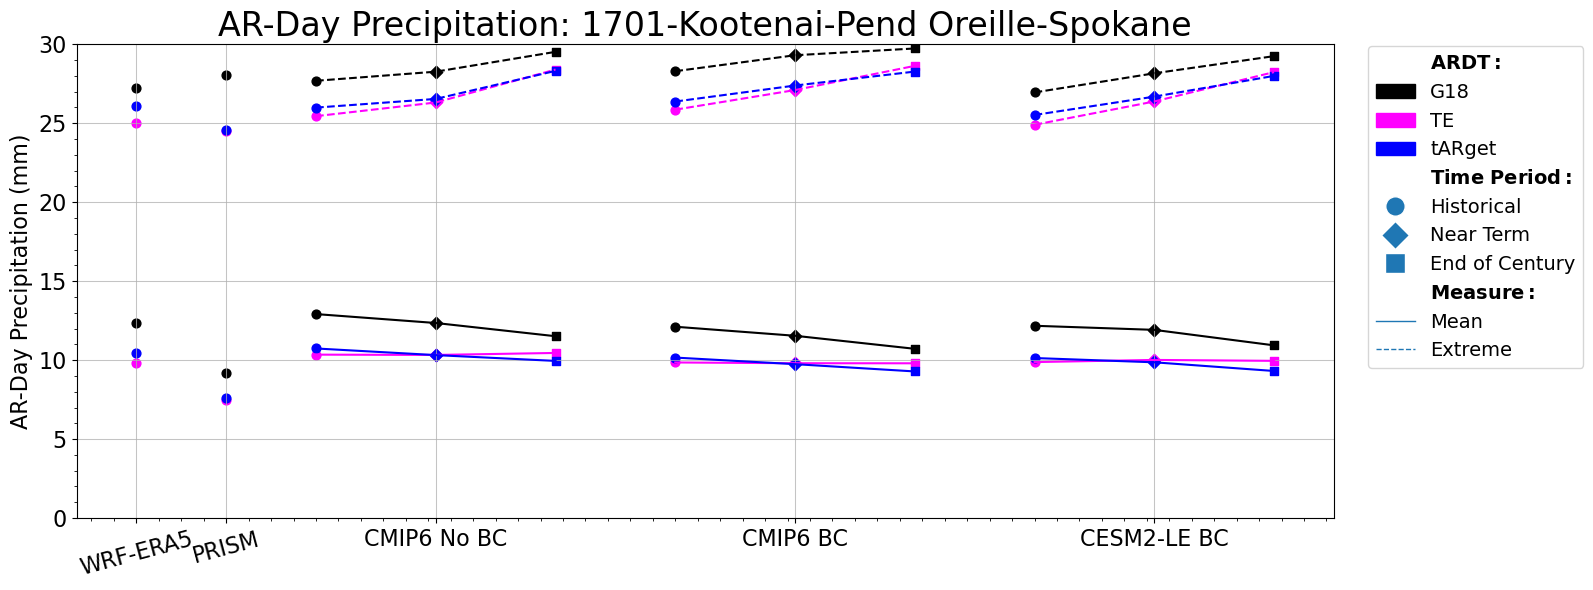

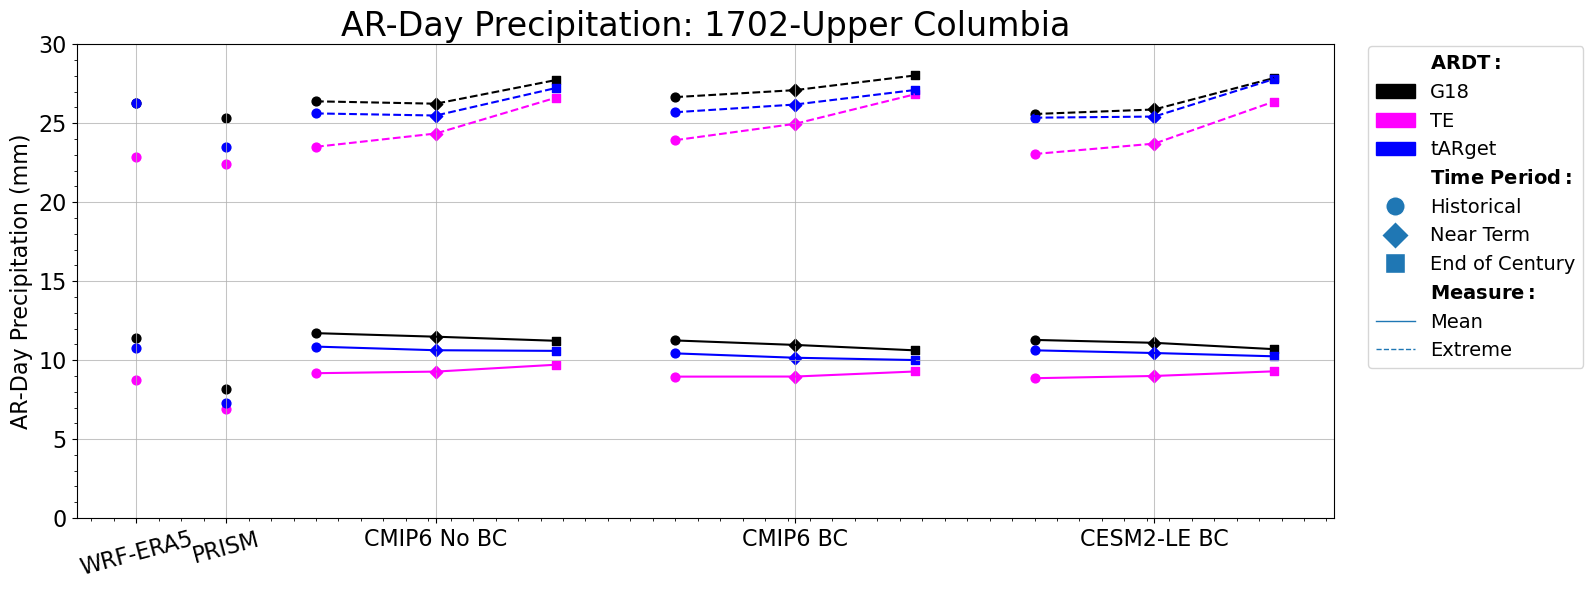

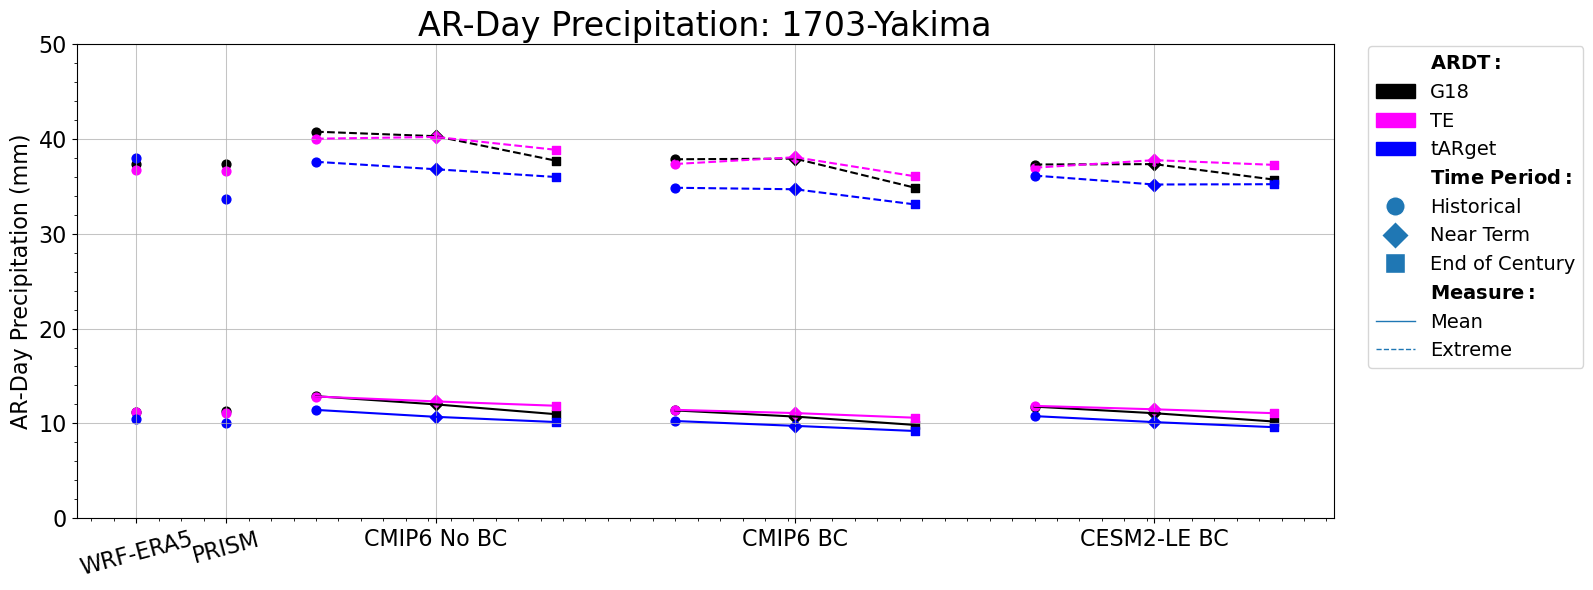

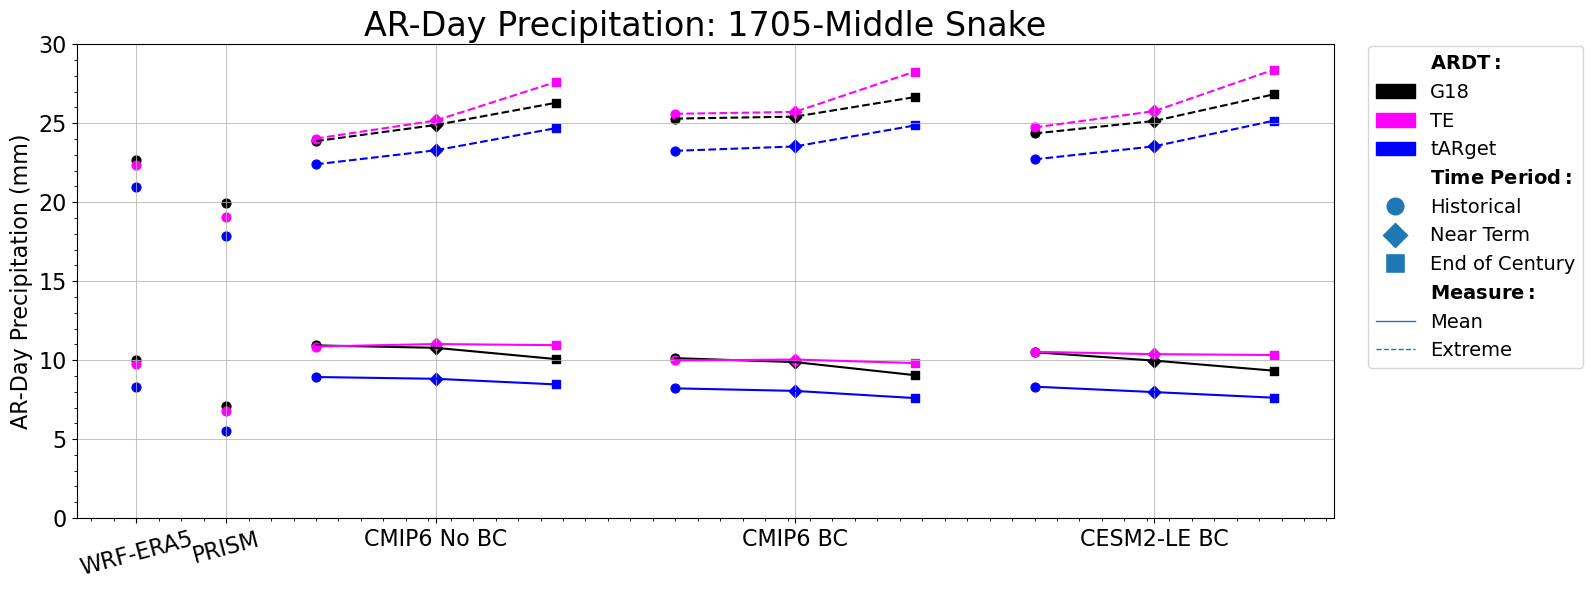

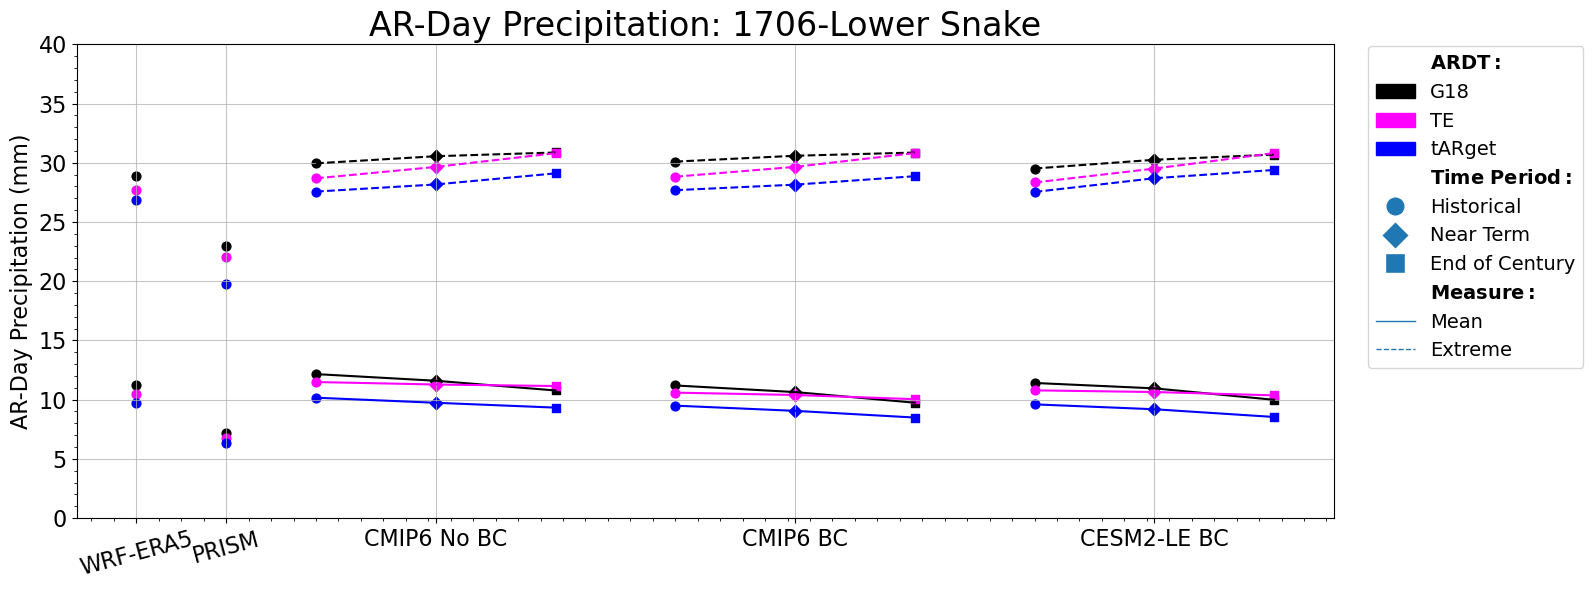

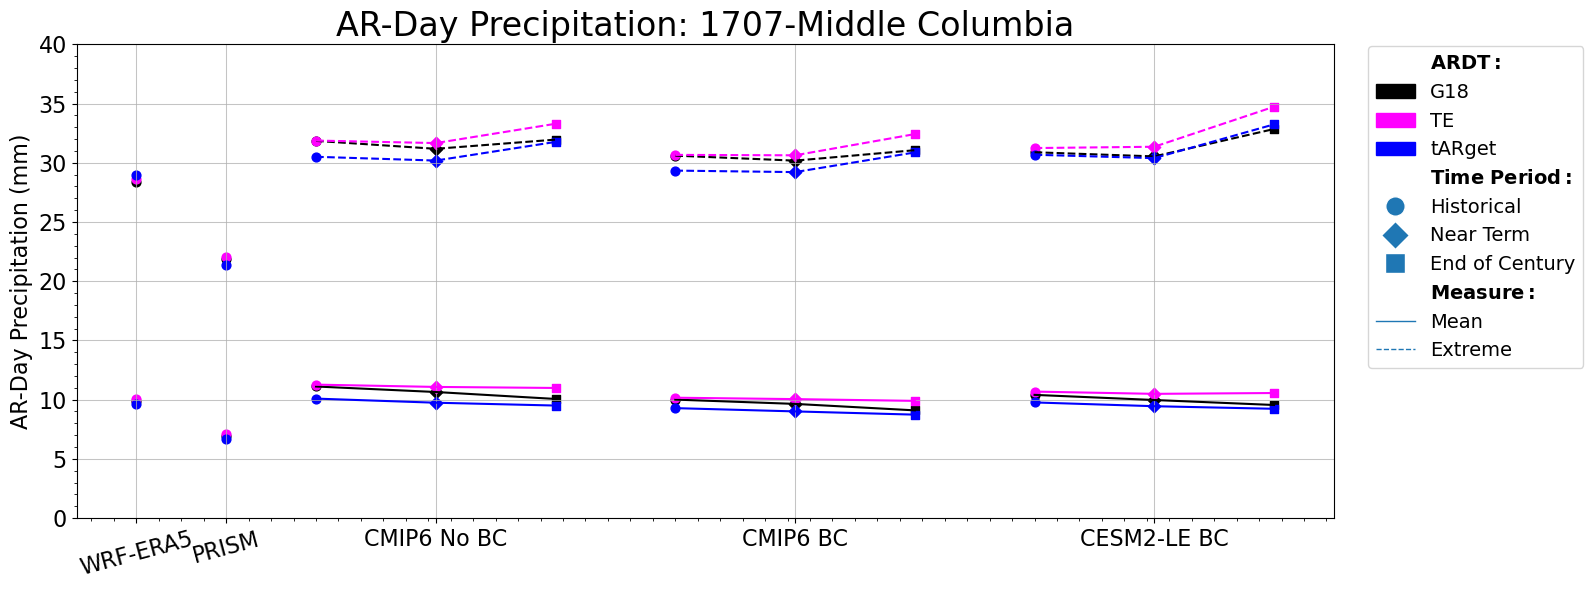

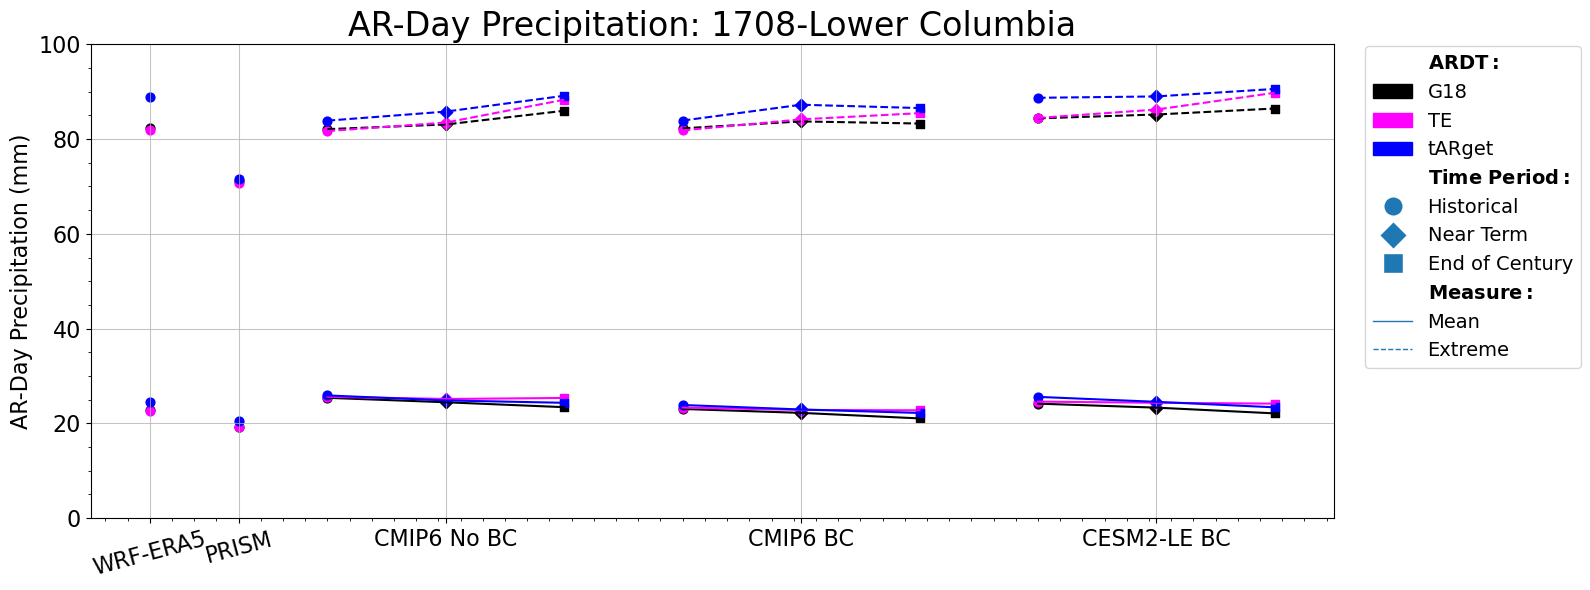

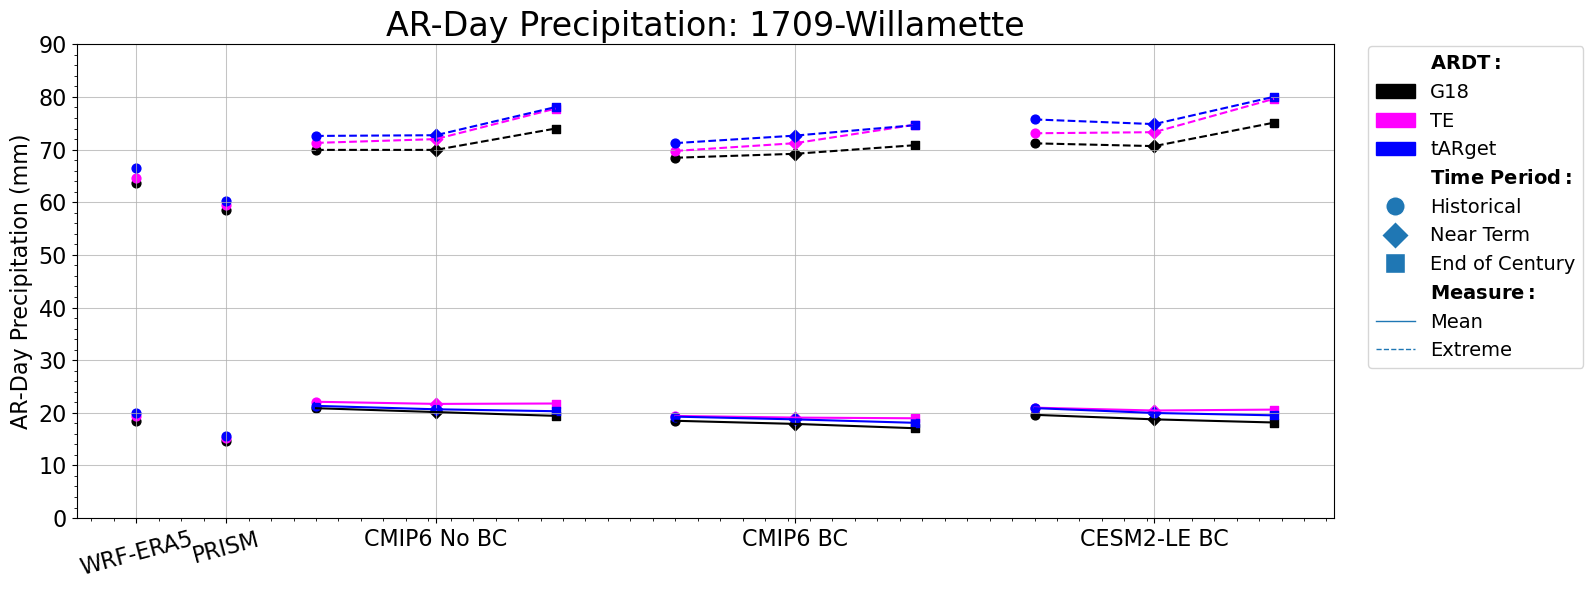

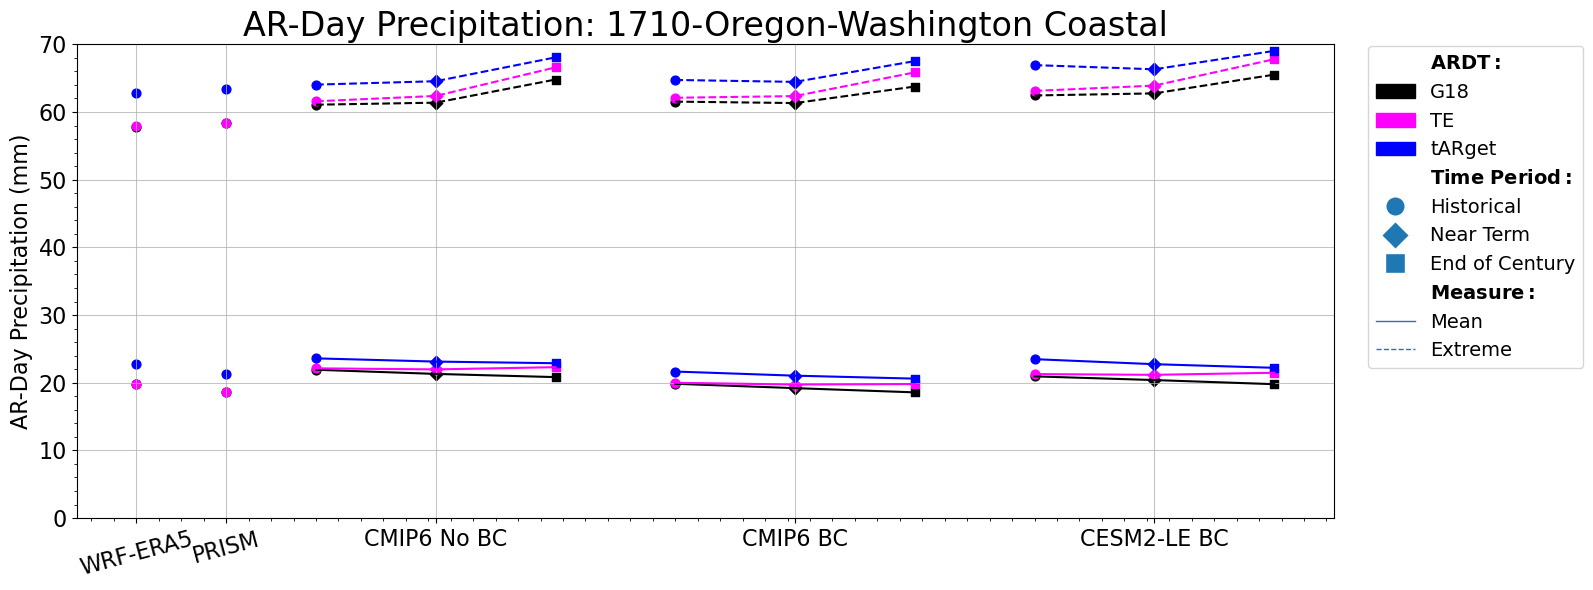

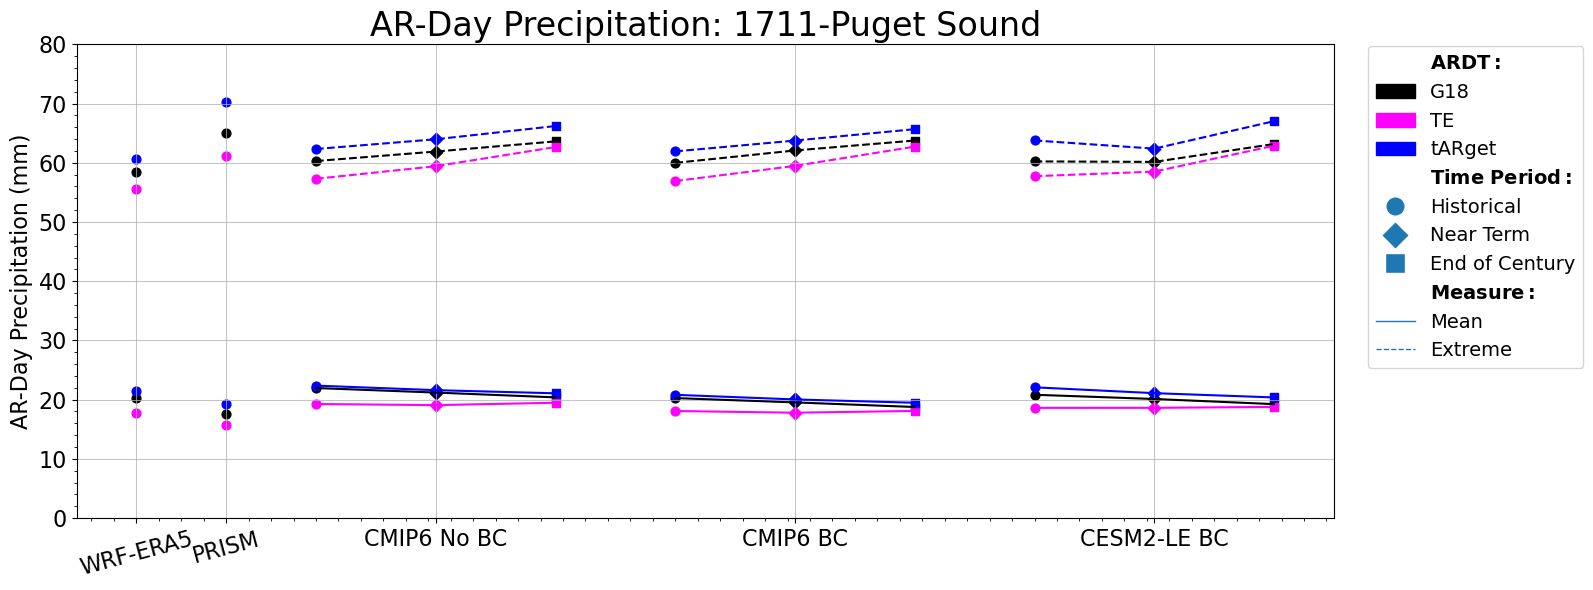

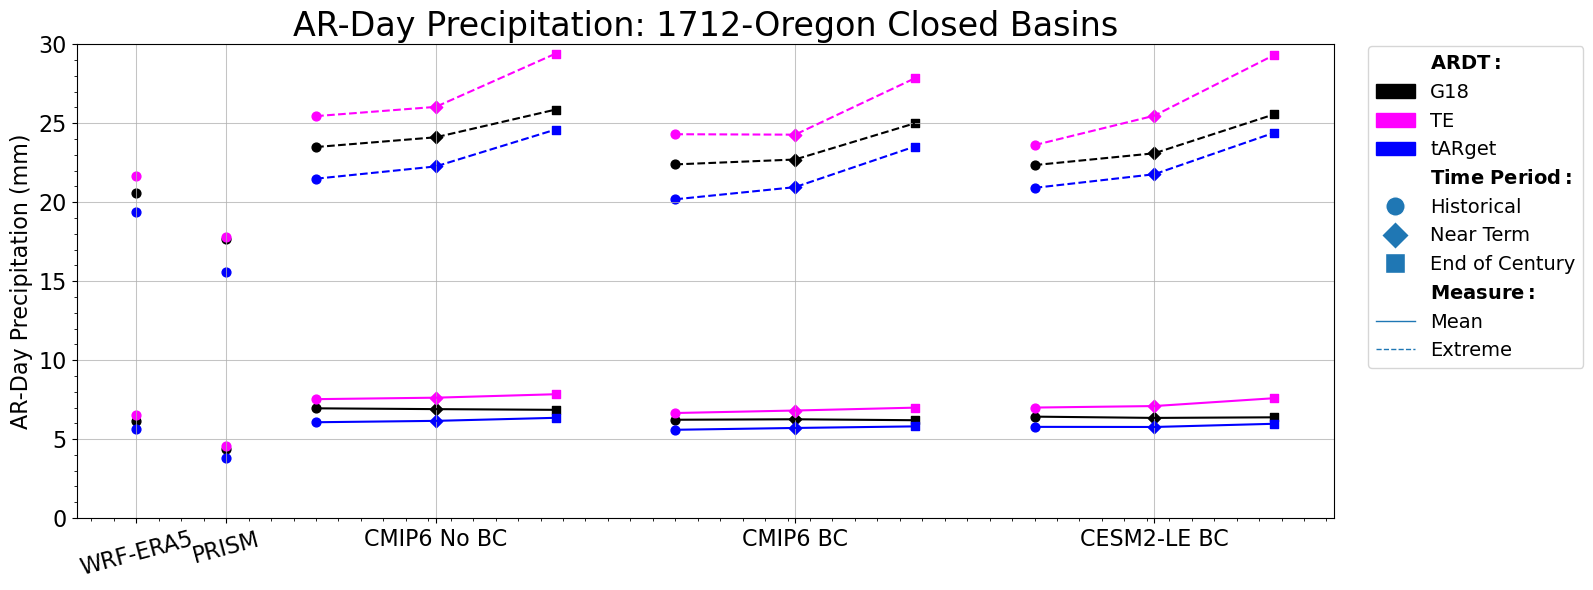

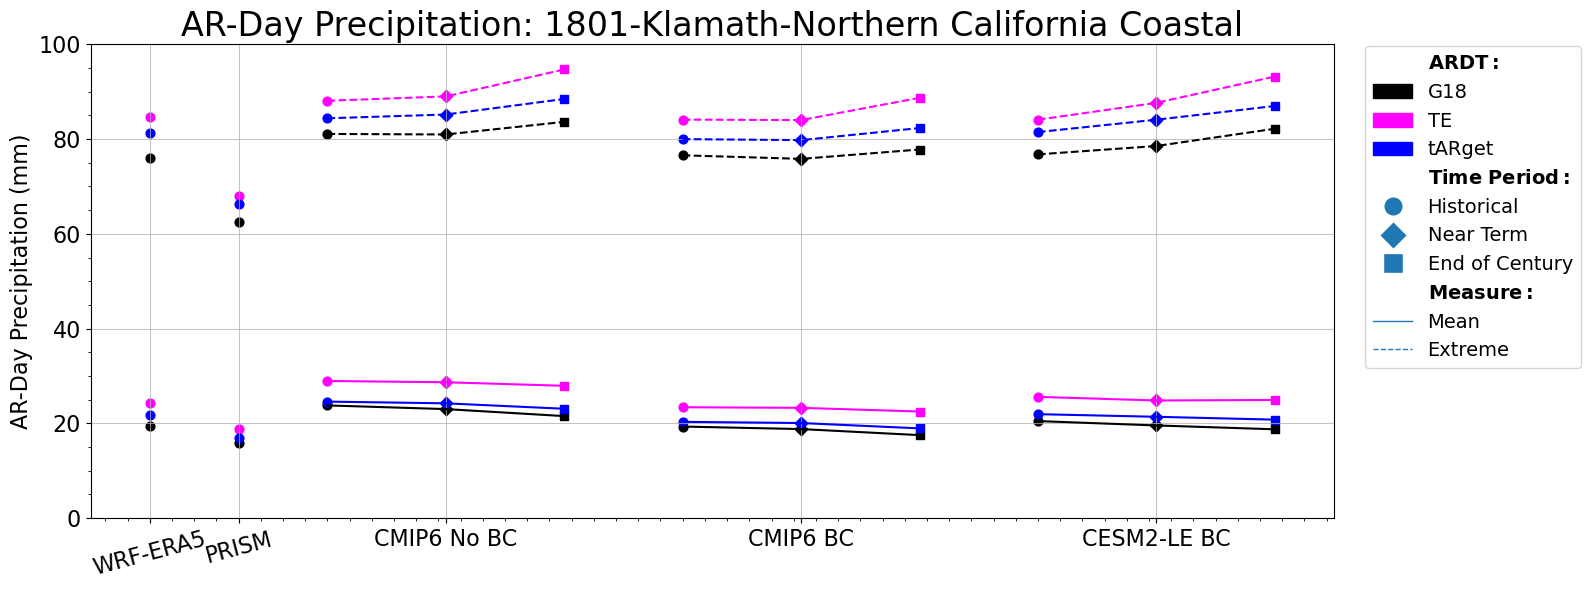

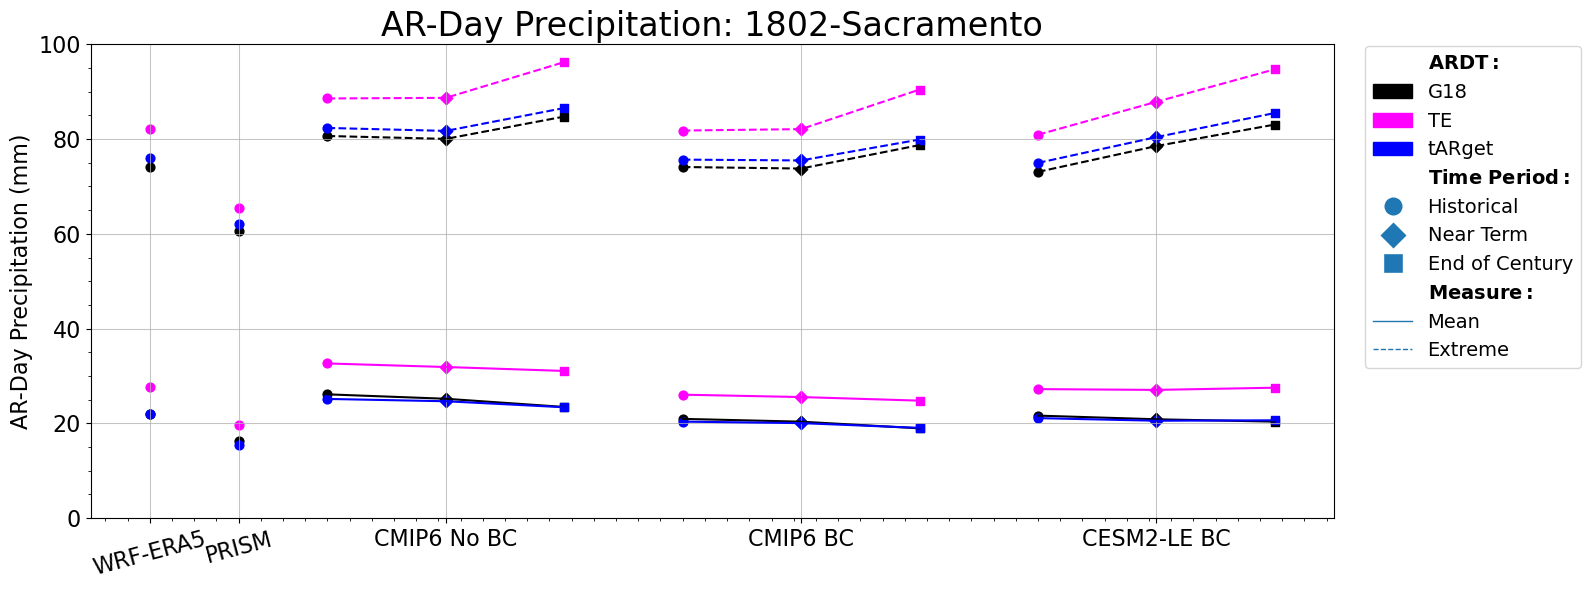

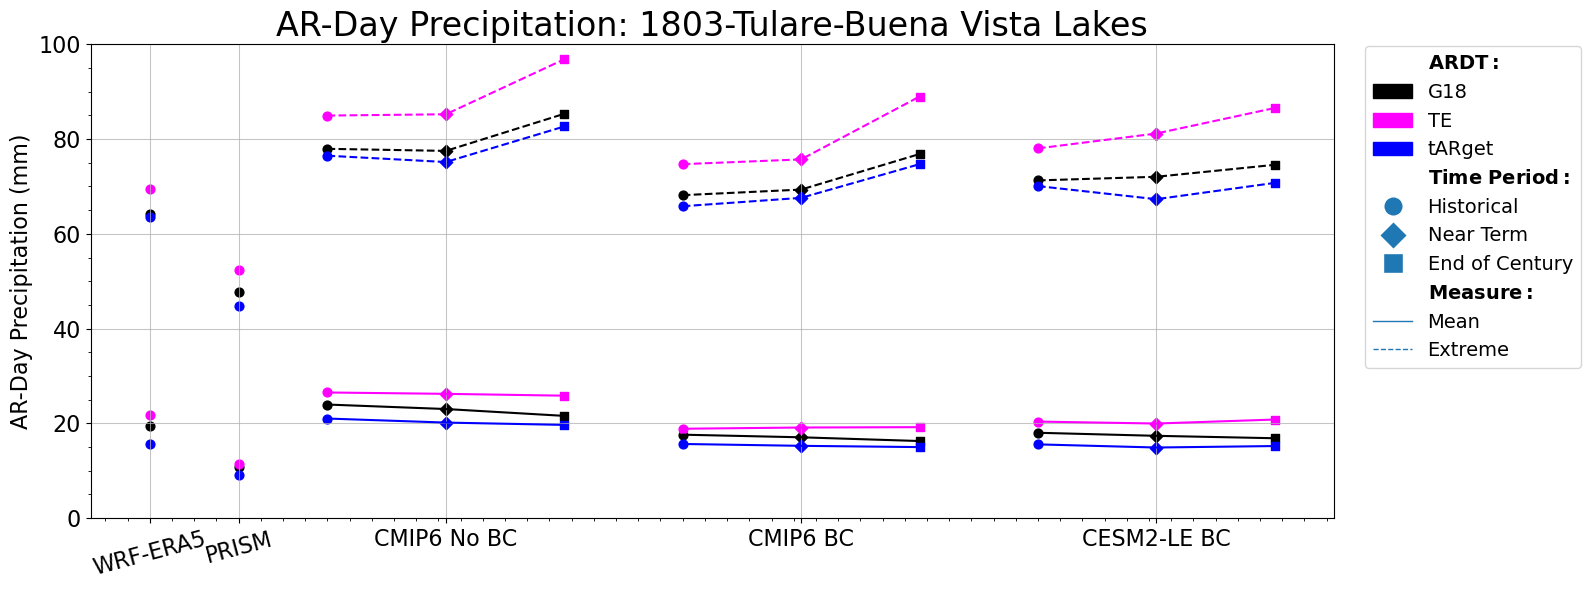

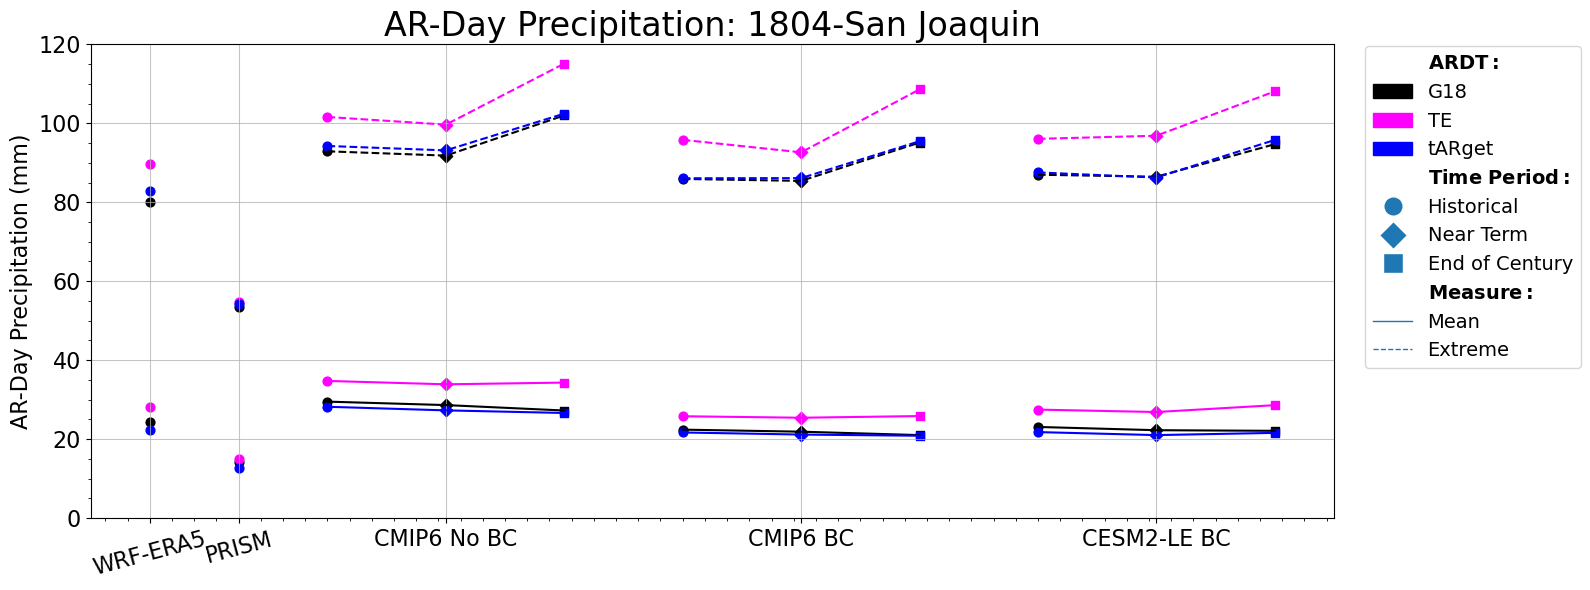

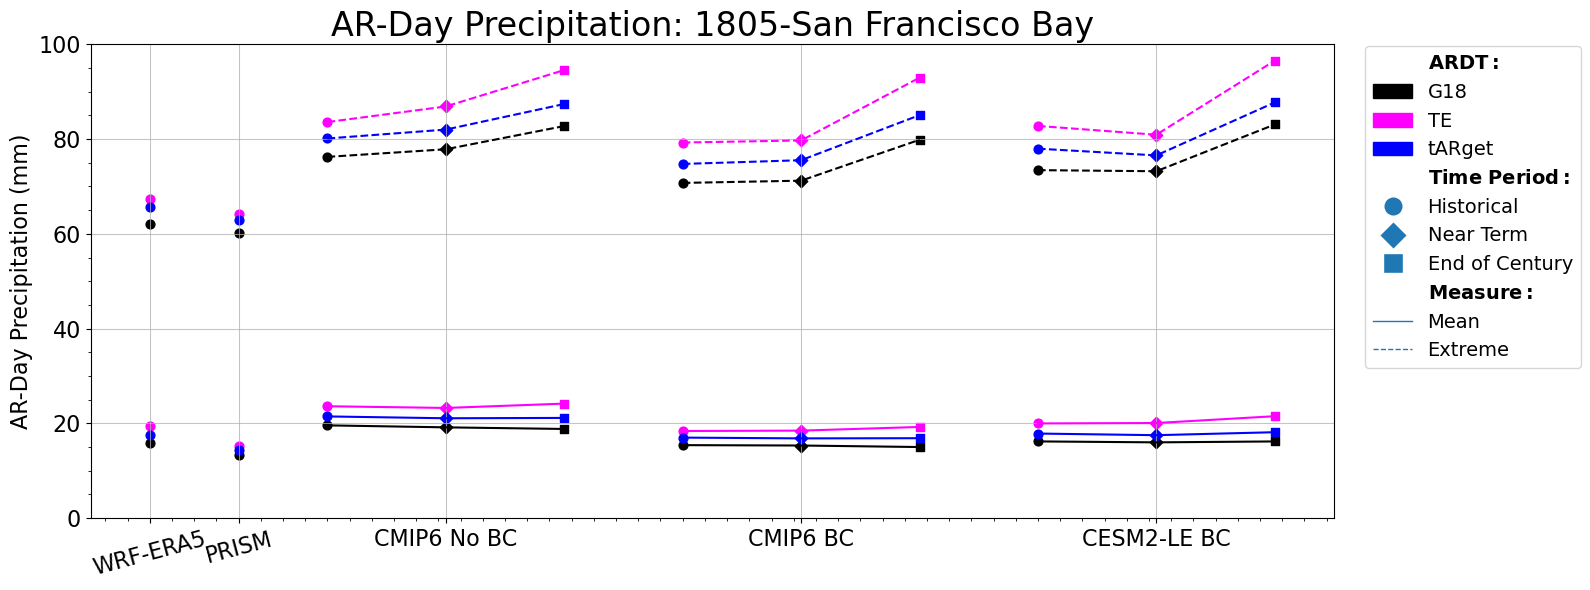

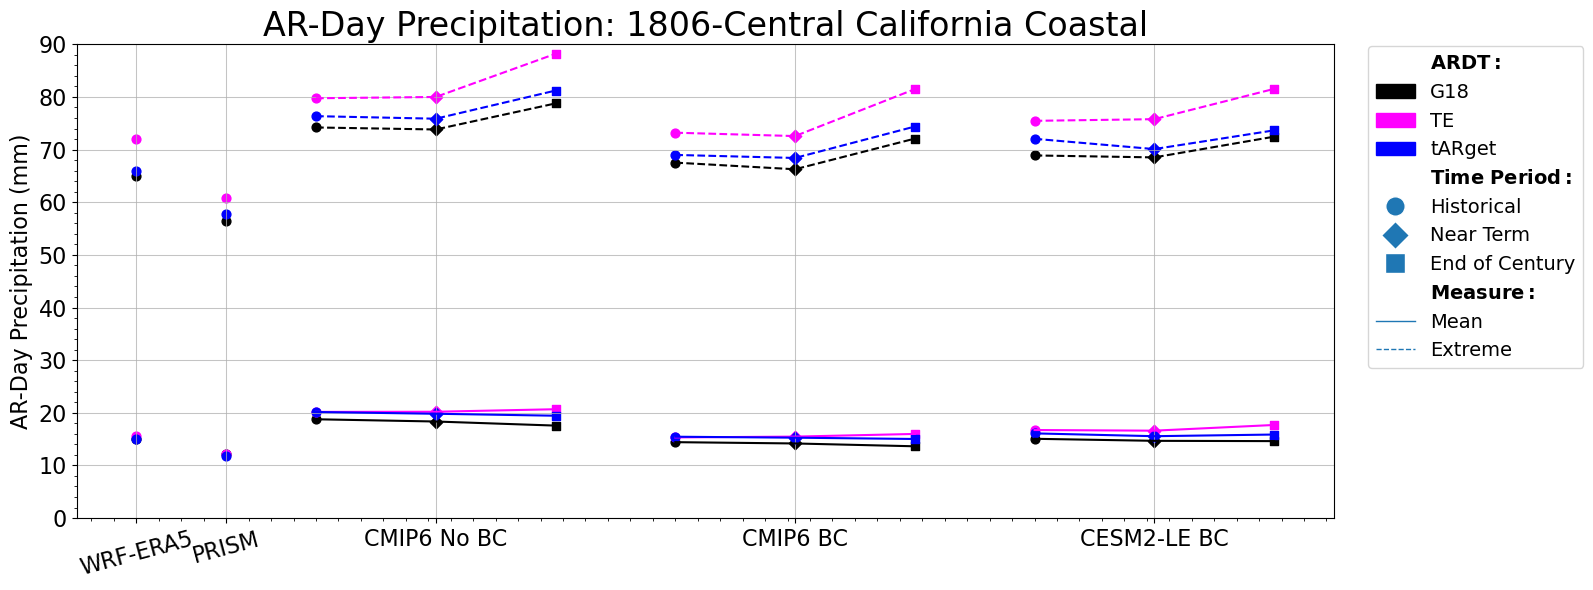

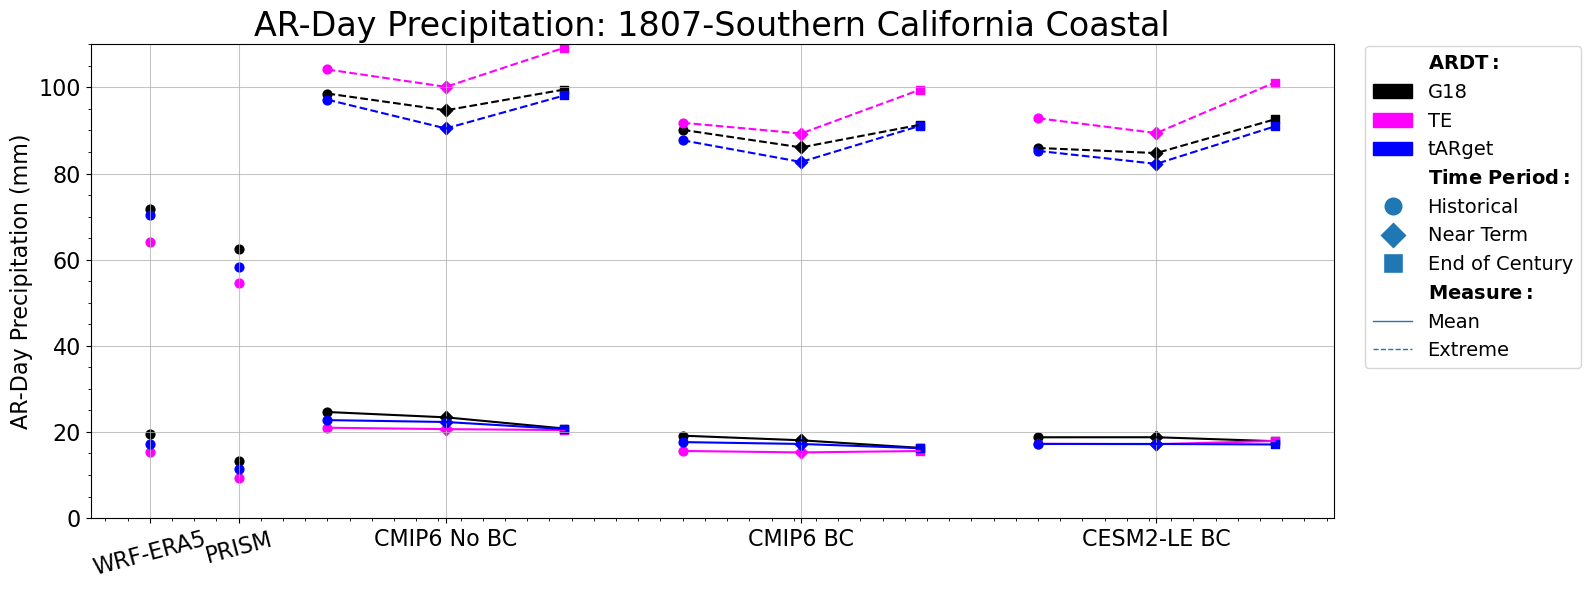

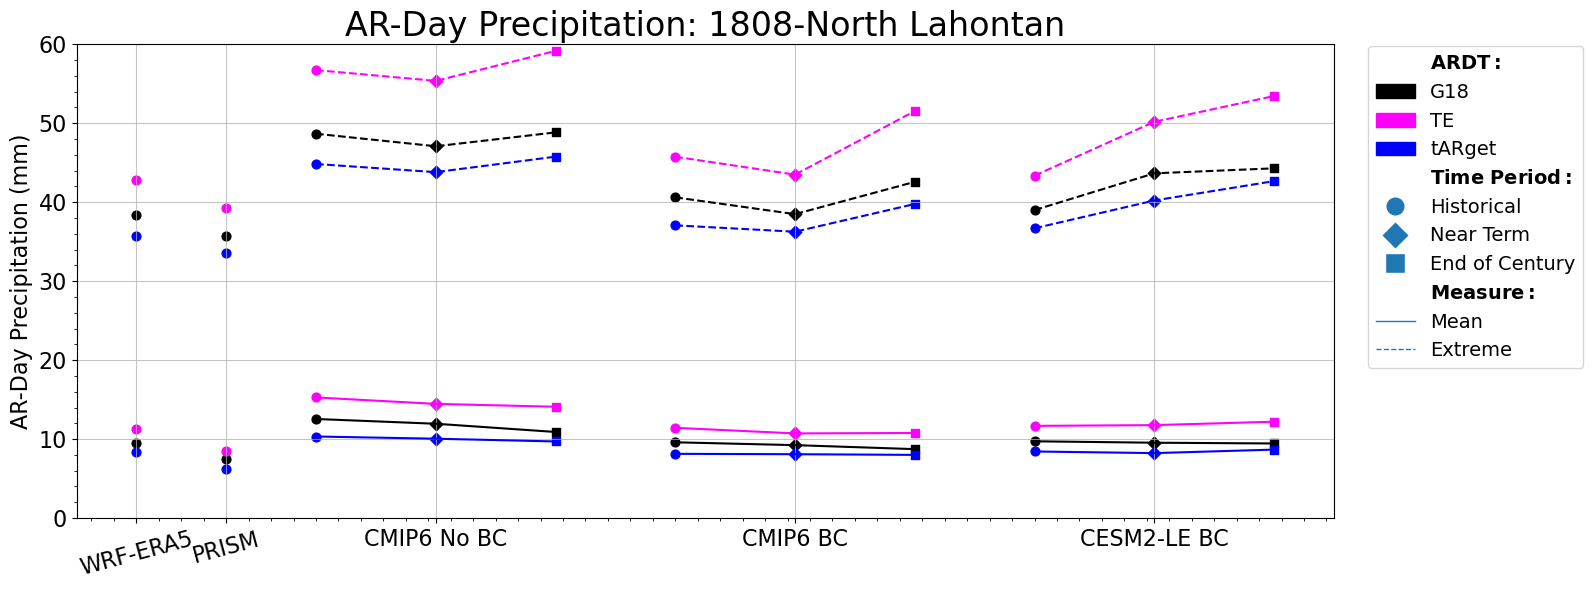

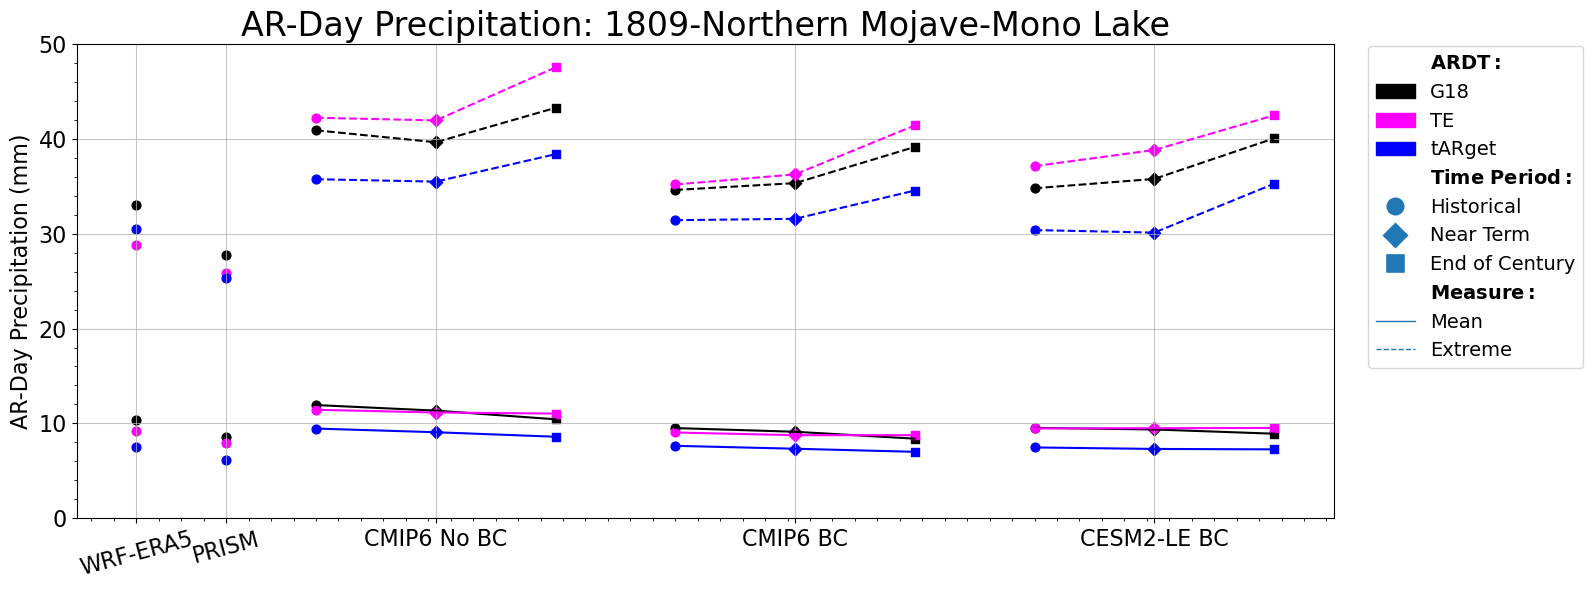

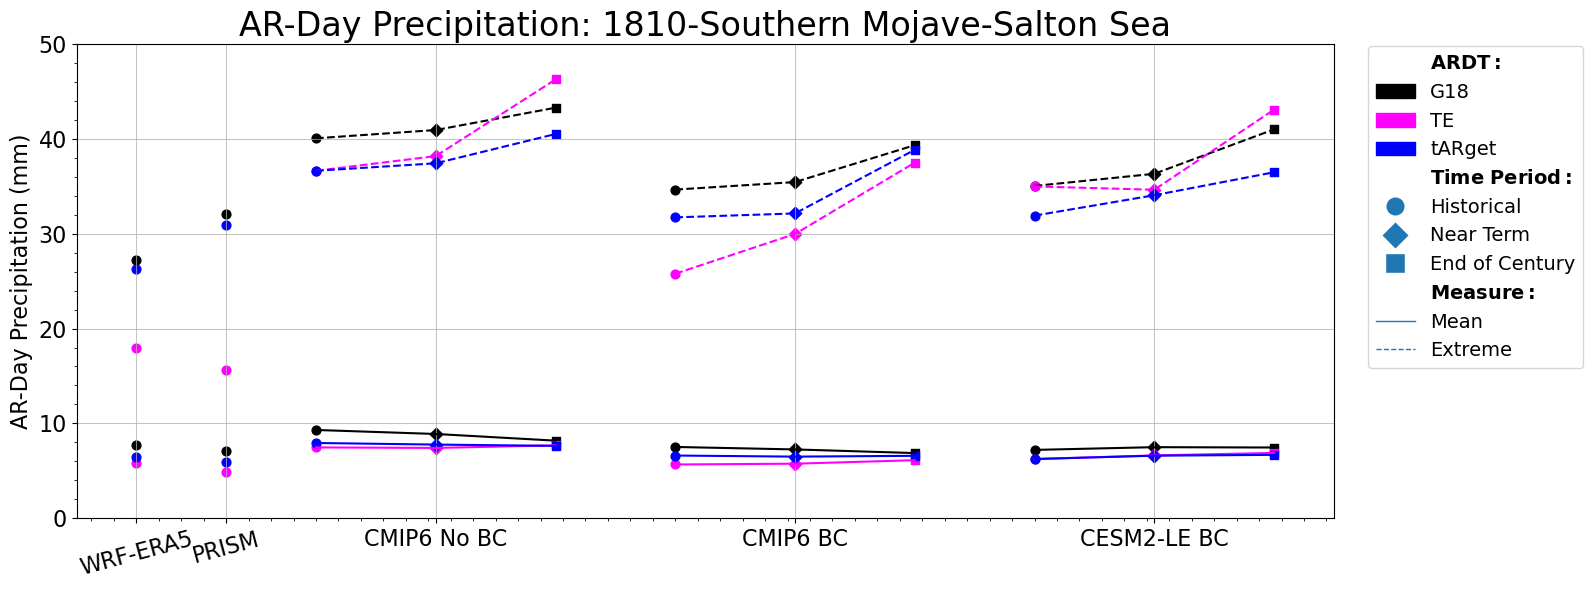

In [5]:
for idx, row in wus_db.iterrows():
    id = row.huc4
    name = row['name']
    name_string = name.replace(" ","_")

    prec_ARday_ws = prec_ARday_all[str(id)]


    all_data = [prec_ARday_ws['wrfera5']['G18']['historical'], prec_ARday_ws['wrfera5']['TE']['historical'], prec_ARday_ws['wrfera5']['tARget']['historical'],
                prec_ARday_ws['prism']['G18']['historical'], prec_ARday_ws['prism']['TE']['historical'], prec_ARday_ws['prism']['tARget']['historical'],
                prec_ARday_ws['cmip6nonbc']['G18']['historical'], prec_ARday_ws['cmip6nonbc']['TE']['historical'], prec_ARday_ws['cmip6nonbc']['tARget']['historical'],
                prec_ARday_ws['cmip6nonbc']['G18']['near-term'], prec_ARday_ws['cmip6nonbc']['TE']['near-term'], prec_ARday_ws['cmip6nonbc']['tARget']['near-term'],
                prec_ARday_ws['cmip6nonbc']['G18']['end-of-century'], prec_ARday_ws['cmip6nonbc']['TE']['end-of-century'], prec_ARday_ws['cmip6nonbc']['tARget']['end-of-century'],
                prec_ARday_ws['cmip6bc']['G18']['historical'], prec_ARday_ws['cmip6bc']['TE']['historical'], prec_ARday_ws['cmip6bc']['tARget']['historical'],
                prec_ARday_ws['cmip6bc']['G18']['near-term'], prec_ARday_ws['cmip6bc']['TE']['near-term'], prec_ARday_ws['cmip6bc']['tARget']['near-term'],
                prec_ARday_ws['cmip6bc']['G18']['end-of-century'], prec_ARday_ws['cmip6bc']['TE']['end-of-century'], prec_ARday_ws['cmip6bc']['tARget']['end-of-century'],
                prec_ARday_ws['cesm2le']['G18']['historical'], prec_ARday_ws['cesm2le']['TE']['historical'], prec_ARday_ws['cesm2le']['tARget']['historical'],
                prec_ARday_ws['cesm2le']['G18']['near-term'], prec_ARday_ws['cesm2le']['TE']['near-term'], prec_ARday_ws['cesm2le']['tARget']['near-term'],
                prec_ARday_ws['cesm2le']['G18']['end-of-century'], prec_ARday_ws['cesm2le']['TE']['end-of-century'], prec_ARday_ws['cesm2le']['tARget']['end-of-century'],
               ]
    
    max_val = 0
    extremes = [get_flier_data(model) for model in all_data]
    for loa in extremes:
        max_val = np.maximum(loa.mean(), max_val)
    max_val_plot = np.ceil(max_val/10)*10
    
    # Line plot: Common tunable parameters
    linecolors = ['black', 'magenta', 'blue']
    labels = ["Historical", "Near-term", "End-of-century"] 
    linestyles = ['solid', 'dashed', 'dotted']

    # Mean
    # CMIP6; Non-BC
    precip_mean_g18_cmip6nonbc = [box_mean(all_data[6]), box_mean(all_data[9]), box_mean(all_data[12])]
    precip_mean_te_cmip6nonbc = [box_mean(all_data[7]), box_mean(all_data[10]), box_mean(all_data[13])]
    precip_mean_tARget_cmip6nonbc = [box_mean(all_data[8]), box_mean(all_data[11]), box_mean(all_data[14])]
    precip_mean_cmip6nonbc = [precip_mean_g18_cmip6nonbc, precip_mean_te_cmip6nonbc, precip_mean_tARget_cmip6nonbc]

    # CMIP6; BC
    precip_mean_g18_cmip6bc = [box_mean(all_data[6+9]), box_mean(all_data[9+9]), box_mean(all_data[12+9])]
    precip_mean_te_cmip6bc = [box_mean(all_data[7+9]), box_mean(all_data[10+9]), box_mean(all_data[13+9])]
    precip_mean_tARget_cmip6bc = [box_mean(all_data[8+9]), box_mean(all_data[11+9]), box_mean(all_data[14+9])]
    precip_mean_cmip6bc = [precip_mean_g18_cmip6bc, precip_mean_te_cmip6bc, precip_mean_tARget_cmip6bc]

    # CESM2-LE
    precip_mean_g18_cesm2le = [box_mean(all_data[6+18]), box_mean(all_data[9+18]), box_mean(all_data[12+18])]
    precip_mean_te_cesm2le = [box_mean(all_data[7+18]), box_mean(all_data[10+18]), box_mean(all_data[13+18])]
    precip_mean_tARget_cesm2le = [box_mean(all_data[8+18]), box_mean(all_data[11+18]), box_mean(all_data[14+18])]
    precip_mean_cesm2le = [precip_mean_g18_cesm2le, precip_mean_te_cesm2le, precip_mean_tARget_cesm2le]

    # Extreme
    # CMIP6; Non-BC
    precip_mean_ext_g18_cmip6nonbc = [extremes[6].mean(), extremes[9].mean(), extremes[12].mean()]
    precip_mean_ext_te_cmip6nonbc = [extremes[7].mean(), extremes[10].mean(), extremes[13].mean()]
    precip_mean_ext_tARget_cmip6nonbc = [extremes[8].mean(), extremes[11].mean(), extremes[14].mean()]
    precip_mean_ext_cmip6nonbc = [precip_mean_ext_g18_cmip6nonbc, precip_mean_ext_te_cmip6nonbc, precip_mean_ext_tARget_cmip6nonbc]

    # CMIP6; BC
    precip_mean_ext_g18_cmip6bc = [extremes[6+9].mean(), extremes[9+9].mean(), extremes[12+9].mean()]
    precip_mean_ext_te_cmip6bc = [extremes[7+9].mean(), extremes[10+9].mean(), extremes[13+9].mean()]
    precip_mean_ext_tARget_cmip6bc = [extremes[8+9].mean(), extremes[11+9].mean(), extremes[14+9].mean()]
    precip_mean_ext_cmip6bc = [precip_mean_ext_g18_cmip6bc, precip_mean_ext_te_cmip6bc, precip_mean_ext_tARget_cmip6bc]

    # CESM2-LE
    precip_mean_ext_g18_cesm2le = [extremes[6+18].mean(), extremes[9+18].mean(), extremes[12+18].mean()]
    precip_mean_ext_te_cesm2le = [extremes[7+18].mean(), extremes[10+18].mean(), extremes[13+18].mean()]
    precip_mean_ext_tARget_cesm2le = [extremes[8+18].mean(), extremes[11+18].mean(), extremes[14+18].mean()]
    precip_mean_ext_cesm2le  = [precip_mean_ext_g18_cesm2le, precip_mean_ext_te_cesm2le, precip_mean_ext_tARget_cesm2le]

    # Bundling up the values calculated above to put into one array to loop over!
    precip_cmip6nonbc = [precip_mean_cmip6nonbc, precip_mean_ext_cmip6nonbc]
    precip_cmip6bc = [precip_mean_cmip6bc, precip_mean_ext_cmip6bc]
    precip_cesm2le = [precip_mean_cesm2le, precip_mean_ext_cesm2le]

    precip_all = [precip_cmip6nonbc, precip_cmip6bc, precip_cesm2le]
    
    precip_wrfera5s = [[box_mean([all_data[0]]),box_mean([all_data[1]]),box_mean([all_data[2]])],
                       [extremes[0].mean(),extremes[1].mean(),extremes[2].mean()],
                      ]

    precip_prisms = [[box_mean([all_data[3]]),box_mean([all_data[4]]),box_mean([all_data[5]])],
                       [extremes[3].mean(),extremes[4].mean(),extremes[5].mean()],
                      ]

    fx, ax = plt.subplots(1, 1, figsize=(16, 6))
    ax.set_xlim(-0.8, 3.4)
    size = 40
    for l in range(3): # l controls the ensemble members
        for k in range(2): # k controls the measure (mean, extreme)
            for i in range(3): # i controls the ARDT used
                xs = [0.4*j+1.2*l for j in range(3)]
                ys = precip_all[l][k][i]
                ax.plot(xs, ys, linestyle=linestyles[k], c=linecolors[i])
                markers = ['o', 'D', 's']
                for xp, yp, mp in zip(xs, ys, markers):
                    ax.scatter([xp], [yp], marker=mp, color=linecolors[i], s=size)

    # Scatter the observationally constrained measures on their own columns.
    for p in range(2):
        for q in range(3):
            ax.scatter([-0.6], precip_wrfera5s[p][q], marker='o', s=size, color=linecolors[q])
            ax.scatter([-0.3], precip_prisms[p][q], marker='o', s=size, color=linecolors[q])
    
    # Set up the figure structure
    ax.minorticks_on()
    ax.grid(which='major', linestyle='-', linewidth=0.75, alpha=0.75)
    ax.set_xticks([-0.6, -0.3, 0.4, 1.6, 2.8])
    ax.set_xticklabels(["WRF-ERA5", "PRISM", "CMIP6 No BC", "CMIP6 BC", "CESM2-LE BC"], fontsize=16)
    xlabels = ax.get_xticklabels()
    for i in range(len(xlabels)):
        if i<2:
            xlabels[i].set_rotation(15)
    ax.set_title(f"AR-Day Precipitation: {id}-{name}", fontsize=24)
    ax.set_ylim(0, max_val_plot)
    ax.set_ylabel('AR-Day Precipitation (mm)', fontsize=16)
    ax.tick_params(axis='y', labelsize=16)

    # Legend is customized for accuracy.
    legendsetup = [mpatches.Patch(color='none', label=r'$\bf{ARDT:}$'),
                   mpatches.Patch(color = 'black', label='G18'),
                   mpatches.Patch(color = 'magenta', label='TE'),
                   mpatches.Patch(color = 'blue', label='tARget'),
                   mpatches.Patch(color='none', label=r'$\bf{Time~Period:}$'),
                   Line2D([0], [0], marker = 'o', color='w', markerfacecolor='#1f77b4', markersize=14, label='Historical'),
                   Line2D([0], [0], marker = 'D', color='w', markerfacecolor='#1f77b4', markersize=14, label='Near Term'),
                   Line2D([0], [0], marker = 's', color='w', markerfacecolor='#1f77b4', markersize=14, label='End of Century'),
                   mpatches.Patch(color='none', label=r'$\bf{Measure:}$'),
                   Line2D([0], [0], linewidth=1, linestyle='solid', label='Mean'),
                   Line2D([0], [0], linewidth=1, linestyle='dashed', label='Extreme'),
                   
    ]
    
    ax.legend(handles=legendsetup, loc='upper right', bbox_to_anchor=(1.2,1), borderaxespad=0.1, fontsize=14)
    fx.tight_layout()
    savepath_bars = '/glade/work/tcorrie/ARdata/Figures/watersheds/bar-plots/'

    fx.savefig(savepath_bars + f'ARdays_lineplot_prec_mean_{id}-{name_string}.png', bbox_inches='tight')
    fx.savefig(f'/glade/work/tcorrie/ARdata/Figures/JoC/ARdays_lineplot_prec_mean_{id}-{name_string}_supp.png', bbox_inches='tight')